# Baku Online Electronics Retailer — Marketing Mix Modeling & Budget Optimisation
**Daily Data Analytics Project · Day 13**

## Business question
*A Baku online electronics retailer spends about **AZN 6.5 million a year** on five channels: TV, outdoor billboards, Meta (Facebook/Instagram), Google Search and YouTube. Each platform reports its own ROAS, and Google Search looks like the clear winner. The CMO asks: **which channels really drive incremental revenue, which are saturated, and how should next year's budget be split — with the same total, and at the profit-optimal total?***

Approach:
1. Clean three years of weekly data (Oct 2023 – Oct 2026, 156 weeks).
2. KPIs and EDA: revenue, spend mix, seasonality, platform-reported ROAS, a Meta "go-dark" test.
3. **Marketing Mix Model written from scratch:** geometric adstock + Hill saturation per channel, controls for trend, seasonality, holidays, promotions and competitor activity. Non-linear parameters by differential evolution on a MAP objective with weakly-informative priors; linear coefficients by bounded least squares (media ≥ 0).
4. Validation: 26-week out-of-time hold-out, residual diagnostics, parameter recovery against the known synthetic ground truth.
5. Revenue decomposition, ROI and **marginal ROI** with moving-block bootstrap intervals, compared with platform-reported ROAS.
6. Response curves and **budget optimisation** (SciPy SLSQP): same budget re-allocated, and the profit-maximising budget.

> Data is **synthetic** (fixed seed), generated by `data/generate_data.py`. Gross margin is assumed to be **30%**, so a channel pays back only above **AZN 3.33 revenue per AZN spent**.

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy.optimize import minimize
import mmm
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.edgecolor": "#898781", "axes.titleweight": "bold"})
CH, L = mmm.CHANNELS, mmm.LABELS
COL = {"tv": "#2a78d6", "outdoor": "#898781", "meta": "#eb6834", "google_search": "#1baf7a", "youtube": "#d03b3b", "base": "#d9d6cf"}
MARGIN = 0.30; BREAK_EVEN = 1 / MARGIN
pd.set_option("display.float_format", "{:,.3f}".format)
raw = mmm.load_raw()
print(raw.shape); raw.head()

(158, 17)


,week_start,revenue_azn_k,orders,tv_spend,outdoor_spend,meta_spend,meta_currency,google_search_spend,youtube_spend,meta_reported_revenue,google_reported_revenue,youtube_reported_revenue,promo_discount_pct,competitor_promo,novruz_week,black_friday_week,new_year_weeks
0,2023-10-16,"1,096.370",3558,73.190,0.000,11.700,AZN,37.840,16.230,111.580,243.960,27.540,0.000,1,0,0,0
1,2023-10-23,"1,201.200",3906,70.980,0.000,18.210,AZN,32.540,0.000,154.240,254.850,13.380,0.000,0,0,0,0
2,2023-10-30,"1,540.430",4956,62.750,0.000,11.650,AZN,22.400,20.740,128.380,315.700,38.370,20.000,0,0,0,0
3,2023-11-06,"1,445.310",4467,100.960,18.800,37.350,AZN,38.330,16.320,222.790,282.740,42.840,0.000,0,0,0,0
4,2023-11-13,"1,410.800",4714,97.000,18.800,20.150,AZN,38.560,0.000,153.690,298.010,23.340,0.000,0,0,0,0


## 1. Data quality check

In [2]:
df, log = mmm.clean(raw)
SP = [f"{c}_spend" for c in CH]
checks = {**log,
 "Weeks after cleaning": f"{len(df)} ({df.week_start.min():%Y-%m-%d} → {df.week_start.max():%Y-%m-%d})",
 "Gaps in the weekly calendar": int((df.week_start.diff().dt.days.dropna() != 7).sum()),
 "Missing values left": int(df.isna().sum().sum()),
 "Negative spend or revenue": int((df[SP + ["revenue_azn_k"]] < 0).sum().sum()),
 "Weeks with zero TV / YouTube / outdoor": f"{(df.tv_spend == 0).sum()} / {(df.youtube_spend == 0).sum()} / {(df.outdoor_spend == 0).sum()}",
}
pd.Series(checks).to_frame("result")

,result
Exact duplicate rows dropped,2
Meta weeks billed in USD → converted at 1.70,6
Missing outdoor invoices → filled from the monthly contract,3
Weeks after cleaning,156 (2023-10-16 → 2026-10-05)
Gaps in the weekly calendar,0
Missing values left,0
Negative spend or revenue,0
Weeks with zero TV / YouTube / outdoor,64 / 60 / 35


Fixes: two duplicated weeks (an export re-run) dropped; six weeks of Meta invoices exported in **USD** instead of AZN converted at 1.70 — left alone, they would look like a 40% spend cut and bias Meta's ROI; three missing outdoor invoices filled with the month's contract value (outdoor is bought in monthly blocks). The calendar is complete: 156 consecutive weeks. Zero-spend weeks for TV, YouTube and outdoor are real (flighting) and are exactly what makes the channels measurable.

## 2. Headline KPIs

In [3]:
yr = df.tail(52)
tot_sp = df[SP].sum().sum()
plat = {"Meta": (df.meta_reported_revenue.sum(), df.meta_spend.sum()),
        "Google Search": (df.google_reported_revenue.sum(), df.google_search_spend.sum()),
        "YouTube": (df.youtube_reported_revenue.sum(), df.youtube_spend.sum())}
yoy = yr.revenue_azn_k.sum() / df.iloc[-104:-52].revenue_azn_k.sum() - 1
K = {
 "Revenue, last 52 weeks": f"AZN {yr.revenue_azn_k.sum() / 1000:,.1f} M (YoY {yoy:+.1%})",
 "Orders, last 52 weeks / average order value": f"{yr.orders.sum():,} / AZN {yr.revenue_azn_k.sum() * 1000 / yr.orders.sum():,.0f}",
 "Media spend, last 52 weeks": f"AZN {yr[SP].sum().sum() / 1000:,.2f} M ({yr[SP].sum().sum() / yr.revenue_azn_k.sum():.1%} of revenue)",
 "Spend mix (3 years)": ", ".join(f"{L[c]} {df[c + '_spend'].sum() / tot_sp:.0%}" for c in CH),
 **{f"Platform-reported ROAS — {k}": f"{r / s:.2f}" for k, (r, s) in plat.items()},
 "Sum of platform-attributed revenue (3 digital channels)": f"{sum(r for r, _ in plat.values()) / df.revenue_azn_k.sum():.1%} of all revenue",
}
pd.Series(K).to_frame("value")

,value
"Revenue, last 52 weeks",AZN 84.8 M (YoY +6.8%)
"Orders, last 52 weeks / average order value","273,559 / AZN 310"
"Media spend, last 52 weeks",AZN 6.54 M (7.7% of revenue)
Spend mix (3 years),"TV 34%, Outdoor 11%, Meta (FB/IG) 22%, Google ..."
Platform-reported ROAS — Meta,7.08
Platform-reported ROAS — Google Search,8.27
Platform-reported ROAS — YouTube,2.63
Sum of platform-attributed revenue (3 digital channels),31.5% of all revenue


Platform dashboards say Google Search returns about AZN 8 per AZN and Meta about 7. TV and outdoor have no dashboard at all, so on platform numbers alone they look like the obvious place to cut. The rest of the notebook tests that view.

## 3. Exploratory analysis

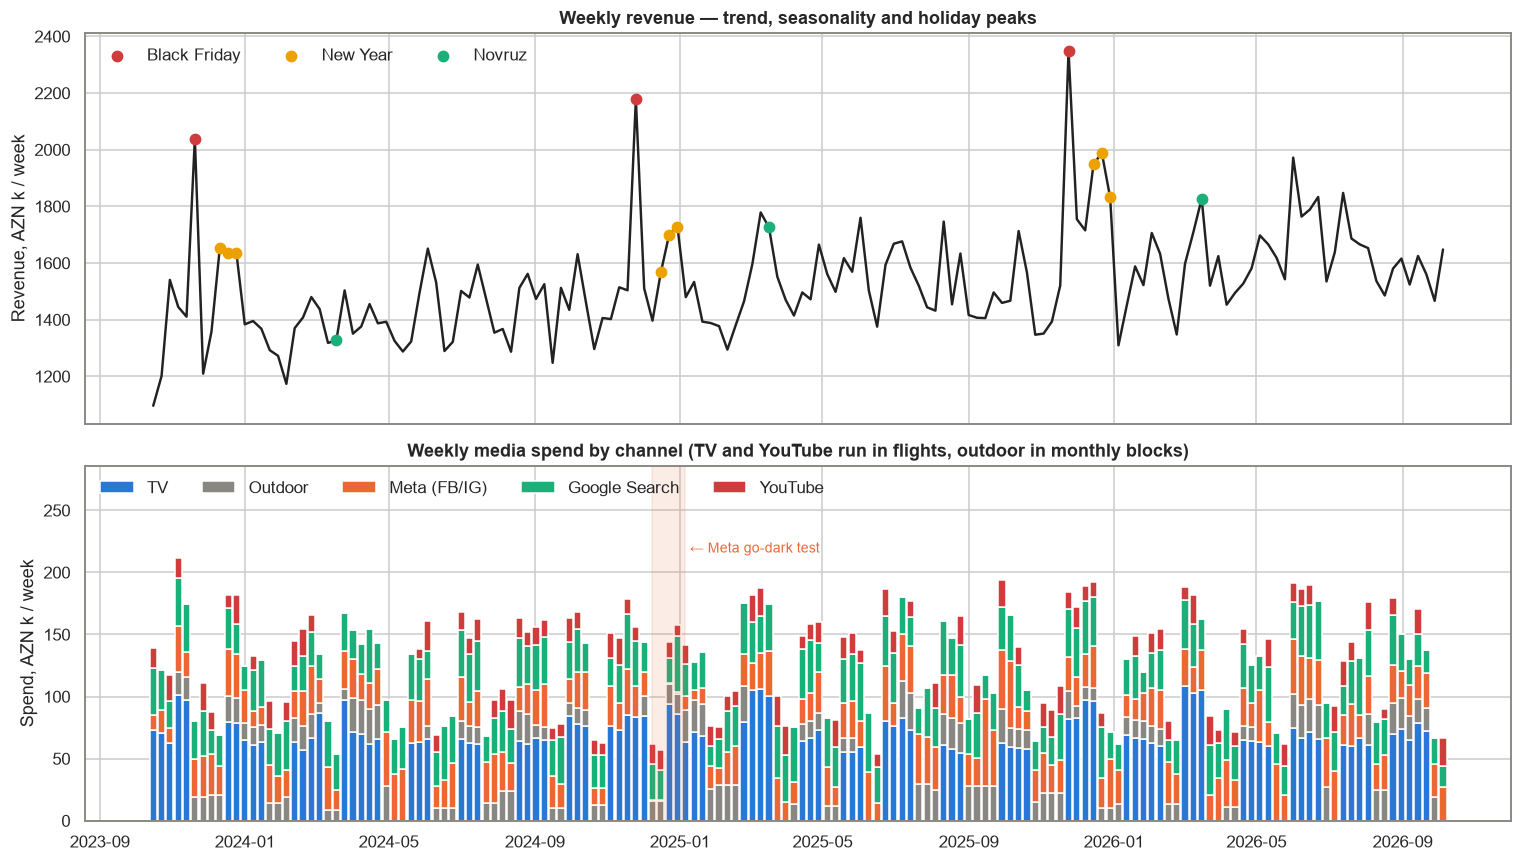

In [4]:
fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={"height_ratios": [1.1, 1]})
ax[0].plot(df.week_start, df.revenue_azn_k, color="#222", lw=1.6)
for col, c, lab in [("black_friday_week", "#d03b3b", "Black Friday"), ("new_year_weeks", "#eda100", "New Year"), ("novruz_week", "#1baf7a", "Novruz")]:
    w = df.loc[df[col] == 1, "week_start"]
    ax[0].scatter(w, df.loc[df[col] == 1, "revenue_azn_k"], color=c, s=45, zorder=3, label=lab)
ax[0].set_ylabel("Revenue, AZN k / week"); ax[0].legend(loc="upper left", frameon=False, ncol=3)
ax[0].set_title("Weekly revenue — trend, seasonality and holiday peaks")
bottom = np.zeros(len(df))
for c in CH:
    ax[1].bar(df.week_start, df[c + "_spend"], bottom=bottom, width=6, color=COL[c], label=L[c]); bottom += df[c + "_spend"].to_numpy()
ax[1].axvspan(df.week_start[60], df.week_start[63] + pd.Timedelta(days=6), color="#eb6834", alpha=.12)
ax[1].set_ylim(0, bottom.max() * 1.35)
ax[1].text(df.week_start[64], bottom.max() * 1.02, " ← Meta go-dark test", color="#eb6834", fontsize=9)
ax[1].set_ylabel("Spend, AZN k / week"); ax[1].legend(ncol=5, frameon=False, loc="upper left", bbox_to_anchor=(0, 1.0))
ax[1].set_title("Weekly media spend by channel (TV and YouTube run in flights, outdoor in monthly blocks)")
plt.tight_layout(); plt.savefig("images/eda_overview.png", bbox_inches="tight"); plt.show()

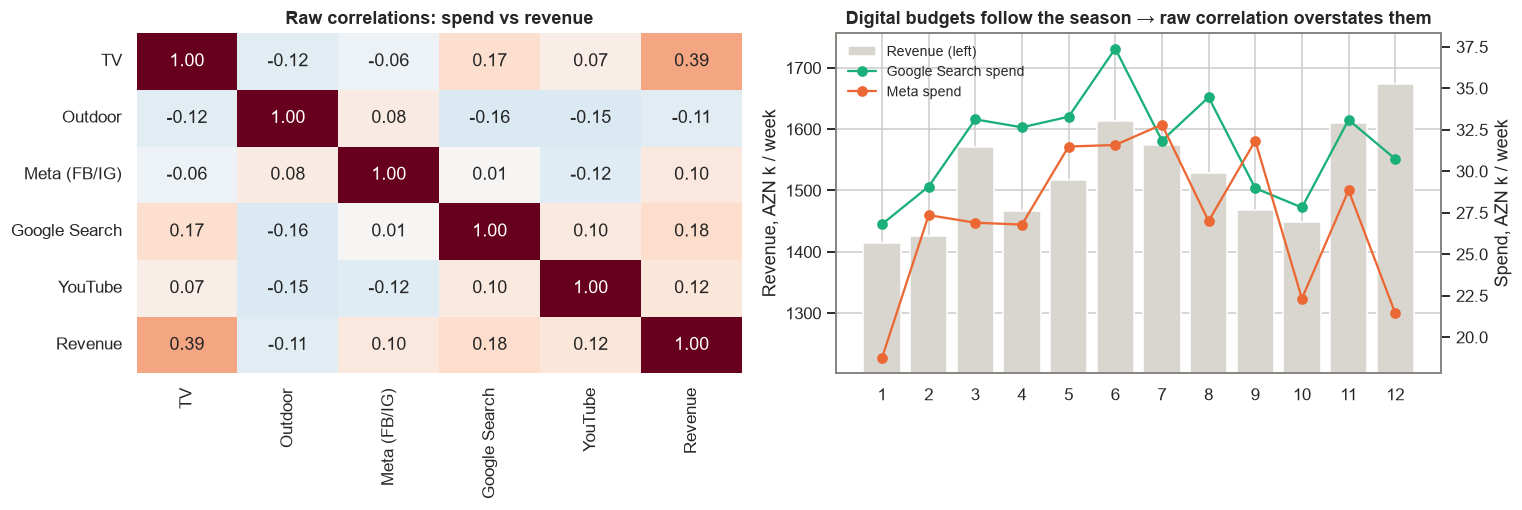

In [5]:
cor = df[SP + ["revenue_azn_k"]].rename(columns={**{c + "_spend": L[c] for c in CH}, "revenue_azn_k": "Revenue"}).corr()
season = mmm.controls(df)[["sin1", "cos1", "black_friday_week", "new_year_weeks"]].sum(axis=1)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
sns.heatmap(cor, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax[0], cbar=False)
ax[0].set_title("Raw correlations: spend vs revenue")
m = df.week_start.dt.month
mo = df.groupby(m).agg(rev=("revenue_azn_k", "mean"), meta=("meta_spend", "mean"), search=("google_search_spend", "mean"))
ax2 = ax[1].twinx()
ax[1].bar(mo.index, mo.rev, color="#d9d6cf", label="Revenue (left)")
ax2.plot(mo.index, mo.search, color=COL["google_search"], marker="o", label="Google Search spend")
ax2.plot(mo.index, mo.meta, color=COL["meta"], marker="o", label="Meta spend")
ax[1].set_xticks(range(1, 13)); ax[1].set_ylim(mo.rev.min() * .85, mo.rev.max() * 1.05)
ax[1].set_ylabel("Revenue, AZN k / week"); ax2.set_ylabel("Spend, AZN k / week"); ax2.grid(False)
ax[1].set_title("Digital budgets follow the season → raw correlation overstates them")
h1, l1 = ax[1].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax[1].legend(h1 + h2, l1 + l2, frameon=False, loc="upper left", fontsize=9)
plt.tight_layout(); plt.savefig("images/eda_correlation_seasonality.png", bbox_inches="tight"); plt.show()

In [6]:
# Meta go-dark test (weeks 60–63, Dec 2024): naive comparison vs the same weeks one year later
dark = df.iloc[60:64]; ctrl = df.iloc[60 + 52:64 + 52]
naive = pd.DataFrame({"go-dark weeks (2024)": [dark.meta_spend.mean(), dark.revenue_azn_k.mean(), dark.meta_reported_revenue.mean()],
                      "same weeks 2025": [ctrl.meta_spend.mean(), ctrl.revenue_azn_k.mean(), ctrl.meta_reported_revenue.mean()]},
                     index=["Meta spend, AZN k/wk", "Revenue, AZN k/wk", "Meta-reported revenue, AZN k/wk"])
naive

,go-dark weeks (2024),same weeks 2025
"Meta spend, AZN k/wk",0.768,31.348
"Revenue, AZN k/wk","1,598.027","1,871.037"
"Meta-reported revenue, AZN k/wk",30.375,213.543


Revenue and every digital budget peak together in November–December, so raw correlations credit the digital channels with part of the seasonal demand. The Meta go-dark weeks can't be read on their own: they fall in December, when revenue is high anyway, and a year-over-year comparison mixes in a year of growth. Controlling for both at once needs a model.

## 4. Marketing Mix Model

**Model:** `revenue_t = base_t + Σ_c β_c · Hill( adstock(spend_c)_t / mean , K_c )`

* **Adstock** (carry-over): `a_t = x_t + θ_c · a_{t−1}`; **Hill** (diminishing returns): `h = a / (a + K_c)`, where `K_c` is the half-saturation point in units of the channel's average adstock.
* **Base:** intercept, linear trend, two annual Fourier pairs, discount depth, competitor promotions and Novruz / Black Friday / New Year dummies.
* **Estimation:** 10 non-linear parameters (θ, K) by differential evolution; for each candidate the 16 linear coefficients are solved exactly by bounded least squares with **β ≥ 0**. Weakly-informative priors keep θ near typical carry-over for each channel type (TV 0.5 ± 0.15, Search 0.05 ± 0.1, …) and `log K ~ N(0, 0.5)`, which stops the saturation point from trading off against the intercept.

First, an honest out-of-time test: fit on the first 130 weeks, forecast the last 26 with actual spend.

In [7]:
train, test = df.iloc[:130], df.iloc[130:]
m_tr = mmm.MMM().fit(train)
pred_all = m_tr.predict(df)
ho = pd.DataFrame({"train (130 wk)": mmm.metrics(train.revenue_azn_k, pred_all.iloc[:130]),
                   "hold-out (26 wk)": mmm.metrics(test.revenue_azn_k, pred_all.iloc[130:])})
naive_pred = df.revenue_azn_k.shift(52).iloc[130:] * (train.revenue_azn_k.tail(52).sum() / train.revenue_azn_k.iloc[-104:-52].sum())
ho["naive: last year × growth"] = mmm.metrics(test.revenue_azn_k, naive_pred)
ho.T.style.format({"MAPE": "{:.2%}", "R2": "{:.3f}", "Bias": "{:+.2%}"})

,MAPE,R2,Bias
train (130 wk),2.01%,0.961,-0.00%
hold-out (26 wk),2.01%,0.901,-0.32%
naive: last year × growth,7.69%,-0.479,+0.19%


In [8]:
model = mmm.MMM().fit(df)
fit = model.predict(df); resid = df.revenue_azn_k - fit
dw = (np.diff(resid) ** 2).sum() / (resid ** 2).sum()
print(f"Full-sample fit: MAPE {mmm.metrics(df.revenue_azn_k, fit)['MAPE']:.2%}, R² {mmm.metrics(df.revenue_azn_k, fit)['R2']:.3f}, Durbin-Watson {dw:.2f}")
params = pd.DataFrame({"decay θ": model.decay, "half-life (weeks)": np.log(.5) / np.log(model.decay.clip(1e-6)),
                       "half-saturation K": model.K, "β (max AZN k/wk)": model.beta}).rename(index=L)
params.style.format({"decay θ": "{:.2f}", "half-life (weeks)": "{:.1f}", "half-saturation K": "{:.2f}", "β (max AZN k/wk)": "{:,.0f}"})

Full-sample fit: MAPE 1.97%, R² 0.960, Durbin-Watson 2.29


,decay θ,half-life (weeks),half-saturation K,β (max AZN k/wk)
TV,0.53,1.1,1.92,615
Outdoor,0.51,1.0,1.02,98
Meta (FB/IG),0.24,0.5,1.04,193
Google Search,0.06,0.3,0.99,159
YouTube,0.46,0.9,1.26,222


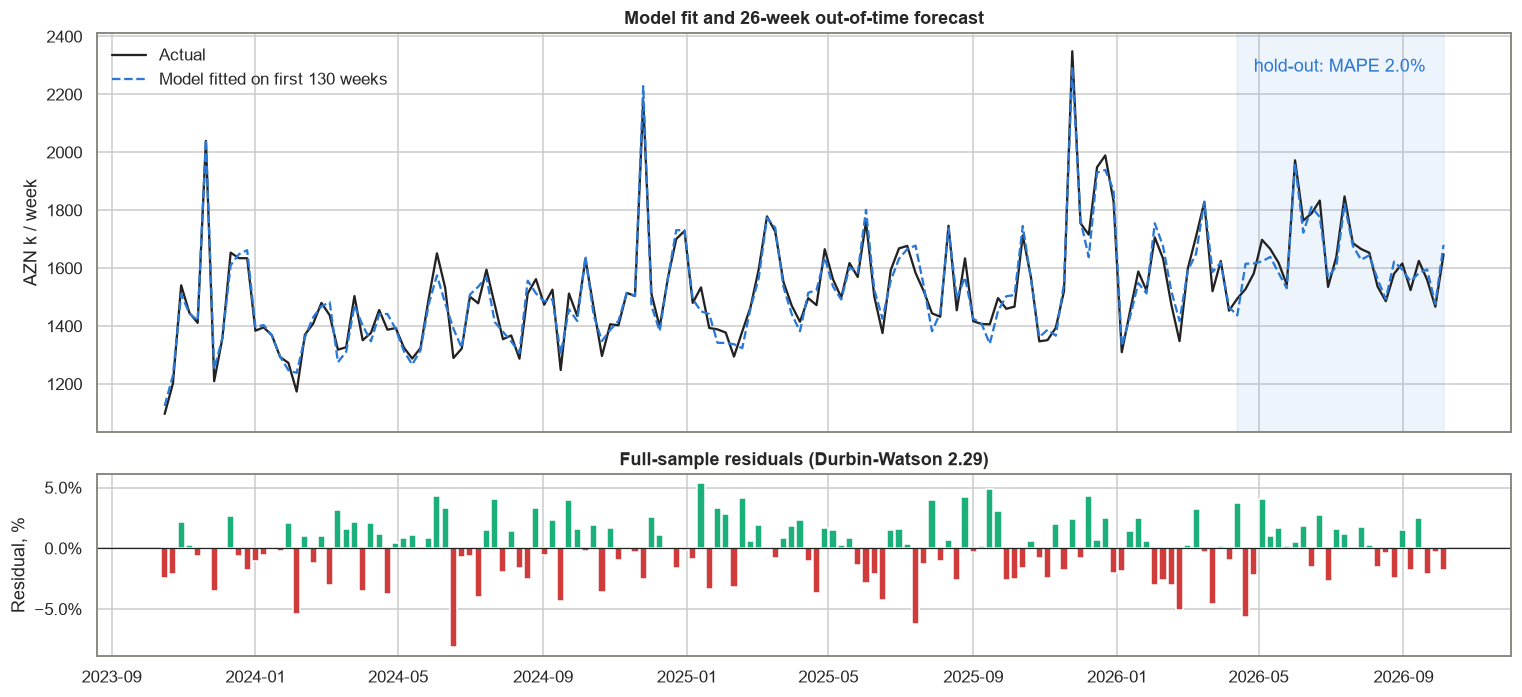

In [9]:
fig, ax = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
ax[0].plot(df.week_start, df.revenue_azn_k, color="#222", lw=1.5, label="Actual")
ax[0].plot(df.week_start, pred_all, color="#2a78d6", lw=1.5, ls="--", label="Model fitted on first 130 weeks")
ax[0].axvspan(test.week_start.iloc[0], test.week_start.iloc[-1], color="#2a78d6", alpha=.08)
ax[0].text(test.week_start.iloc[2], df.revenue_azn_k.max() * .97,
           f"hold-out: MAPE {ho.loc['MAPE', 'hold-out (26 wk)']:.1%}", color="#2a78d6")
ax[0].set_ylabel("AZN k / week"); ax[0].legend(frameon=False, loc="upper left")
ax[0].set_title("Model fit and 26-week out-of-time forecast")
ax[1].bar(df.week_start, resid / df.revenue_azn_k, width=6, color=np.where(resid > 0, "#1baf7a", "#d03b3b"))
ax[1].axhline(0, color="#222", lw=.8); ax[1].set_ylabel("Residual, %")
ax[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax[1].set_title(f"Full-sample residuals (Durbin-Watson {dw:.2f})")
plt.tight_layout(); plt.savefig("images/model_fit.png", bbox_inches="tight"); plt.show()

The model forecasts six months it has never seen with about 2% error and almost no bias, far better than "last year × growth", and the residuals show no autocorrelation (Durbin-Watson ≈ 2). That is the minimum bar before reading anything off the media coefficients.

## 5. What drives revenue? Decomposition

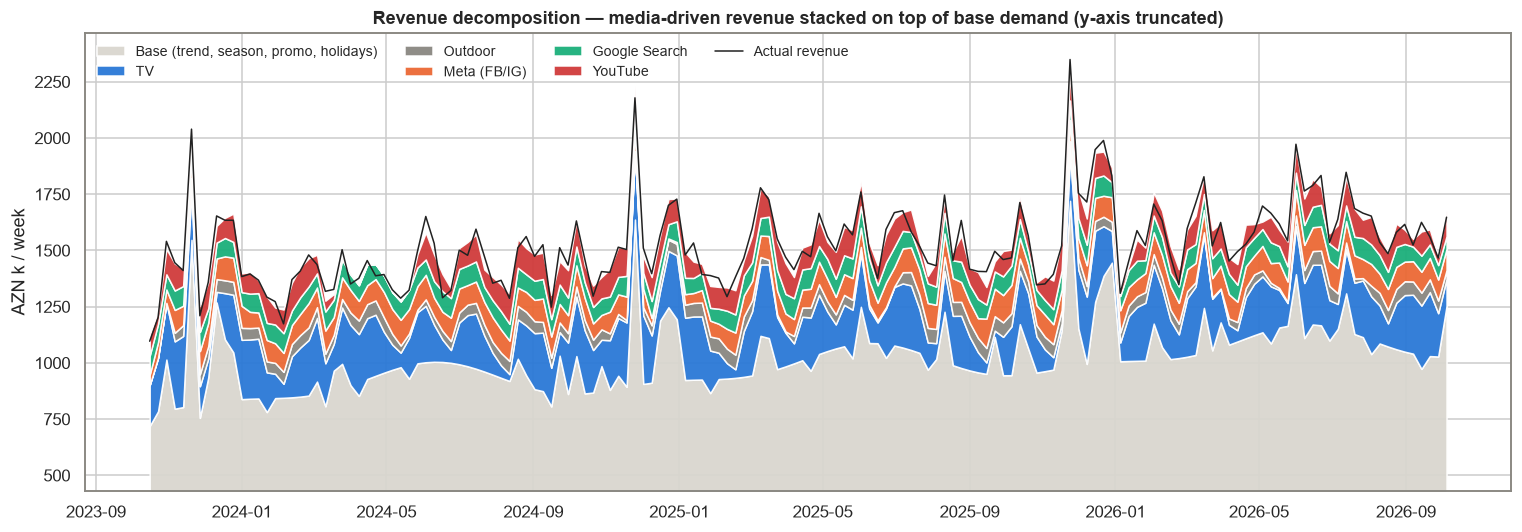

Share of revenue: base 67.1%, TV 12.9%, Outdoor 2.9%, Meta (FB/IG) 6.0%, Google Search 5.2%, YouTube 5.9%
Media-driven revenue: 32.9%


In [10]:
contrib = model.contributions(df)
fig, ax = plt.subplots(figsize=(14, 5))
ax.stackplot(df.week_start, [contrib.base] + [contrib[c] for c in CH], colors=[COL["base"]] + [COL[c] for c in CH],
             labels=["Base (trend, season, promo, holidays)"] + [L[c] for c in CH], alpha=.95)
ax.plot(df.week_start, df.revenue_azn_k, color="#222", lw=1, label="Actual revenue")
ax.set_ylim(contrib.base.min() * .6, None); ax.set_ylabel("AZN k / week")
ax.legend(ncol=4, frameon=False, loc="upper left", fontsize=9)
ax.set_title("Revenue decomposition — media-driven revenue stacked on top of base demand (y-axis truncated)")
plt.tight_layout(); plt.savefig("images/decomposition.png", bbox_inches="tight"); plt.show()
share = (contrib.sum() / contrib.sum().sum()).rename(index=L)
print("Share of revenue:", ", ".join(f"{k} {v:.1%}" for k, v in share.items()))
print(f"Media-driven revenue: {share.drop('base').sum():.1%}")

## 6. ROI, marginal ROI and platform ROAS

In [11]:
spend_tot = model._spend(df).sum()
roi = contrib[CH].sum() / spend_tot
boot = mmm.block_bootstrap_roi(model, df, n_boot=400, block=8)
mroi = pd.Series({c: model.marginal_roi(df, c) for c in CH})
platform = pd.Series({"meta": df.meta_reported_revenue.sum() / df.meta_spend.sum(),
                      "google_search": df.google_reported_revenue.sum() / df.google_search_spend.sum(),
                      "youtube": df.youtube_reported_revenue.sum() / df.youtube_spend.sum()})
R = pd.DataFrame({"spend, AZN M (3y)": spend_tot / 1000, "incremental revenue, AZN M": contrib[CH].sum() / 1000,
                  "ROI": roi, "ROI 90% low": boot.quantile(.05), "ROI 90% high": boot.quantile(.95),
                  "marginal ROI": mroi, "platform ROAS": platform,
                  "profit per AZN (ROI×30% − 1)": roi * MARGIN - 1})
R.rename(index=L).style.format("{:,.2f}", na_rep="—")

,"spend, AZN M (3y)","incremental revenue, AZN M",ROI,ROI 90% low,ROI 90% high,marginal ROI,platform ROAS,profit per AZN (ROI×30% − 1)
Google Search,4.94,12.28,2.49,1.17,3.93,1.23,8.27,-0.25
Meta (FB/IG),4.25,14.31,3.36,2.56,4.27,1.69,7.08,0.01
Outdoor,2.24,6.89,3.08,2.19,4.03,1.48,—,-0.08
TV,6.68,30.82,4.61,4.34,4.90,2.90,—,0.38
YouTube,1.56,14.04,8.98,7.67,10.20,4.76,2.63,1.69


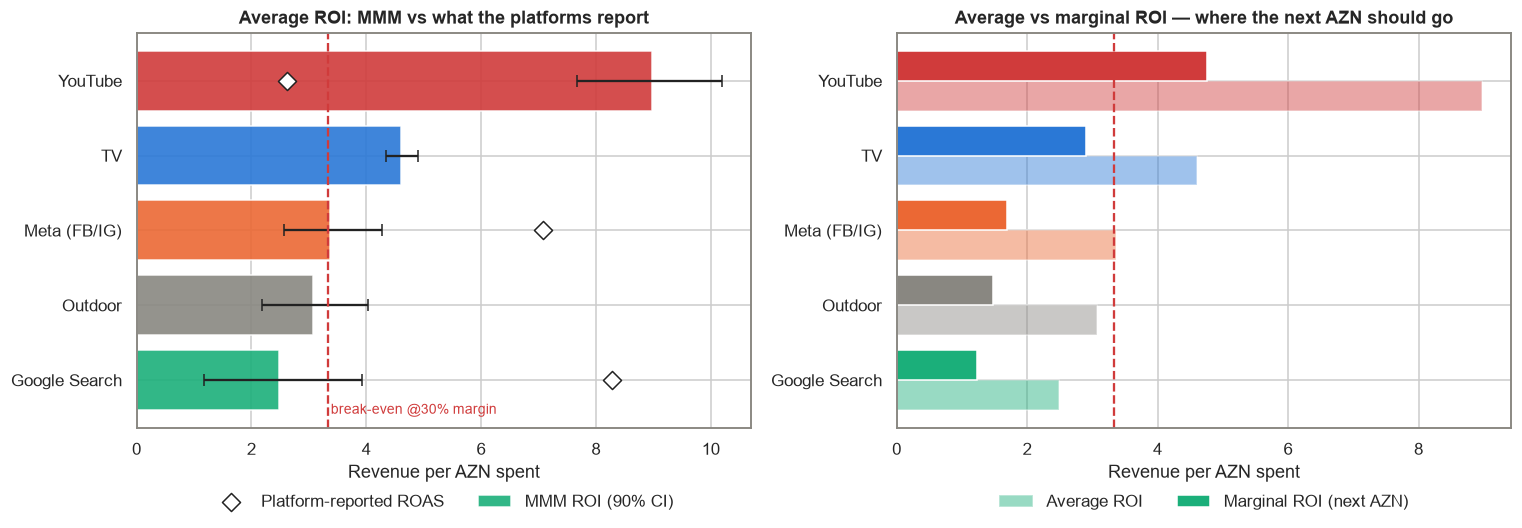

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
order = roi.sort_values().index
y = np.arange(len(order))
ax[0].barh(y, roi[order], color=[COL[c] for c in order], alpha=.9, label="MMM ROI (90% CI)")
ax[0].errorbar(roi[order], y, xerr=[roi[order] - boot.quantile(.05)[order], boot.quantile(.95)[order] - roi[order]],
               fmt="none", ecolor="#222", capsize=4)
ax[0].scatter(platform.reindex(order), y, marker="D", s=70, color="white", edgecolor="#222", zorder=3, label="Platform-reported ROAS")
ax[0].axvline(BREAK_EVEN, color="#d03b3b", ls="--"); ax[0].text(BREAK_EVEN + .05, -.45, "break-even @30% margin", color="#d03b3b", fontsize=9)
ax[0].set_yticks(y, [L[c] for c in order]); ax[0].set_xlabel("Revenue per AZN spent")
ax[0].legend(frameon=False, loc="upper center", bbox_to_anchor=(.5, -.13), ncol=2); ax[0].set_title("Average ROI: MMM vs what the platforms report")
ax[1].barh(y - .2, roi[order], height=.4, color=[COL[c] for c in order], alpha=.45, label="Average ROI")
ax[1].barh(y + .2, mroi[order], height=.4, color=[COL[c] for c in order], label="Marginal ROI (next AZN)")
ax[1].axvline(BREAK_EVEN, color="#d03b3b", ls="--")
ax[1].set_yticks(y, [L[c] for c in order]); ax[1].set_xlabel("Revenue per AZN spent")
ax[1].legend(frameon=False, loc="upper center", bbox_to_anchor=(.5, -.13), ncol=2); ax[1].set_title("Average vs marginal ROI — where the next AZN should go")
plt.tight_layout(); plt.savefig("images/roi_comparison.png", bbox_inches="tight"); plt.show()

Platform ROAS and MMM disagree most on Google Search: last-click gives Search the credit for buyers who were sent to Google by TV and YouTube, plus people who would have searched for the store anyway. Meta's in-platform attribution also over-counts (view-through, people who would have bought anyway). YouTube, which the platform barely credits, has the highest incremental ROI and is still far from saturated. The **marginal** ROI is the number that matters for the next budget decision: it is below the average for every channel because of diminishing returns.

In [13]:
# Synthetic data → we can check how close the model gets to the true parameters
gt = json.load(open("data/ground_truth.json"))
chk = pd.DataFrame({"true ROI": {c: gt[c]["roi"] for c in CH}, "MMM ROI": roi, "90% CI covers truth": {
    c: bool(boot.quantile(.05)[c] <= gt[c]["roi"] <= boot.quantile(.95)[c]) for c in CH},
    "true decay": {c: gt[c]["decay"] for c in CH}, "MMM decay": model.decay,
    "platform ROAS": platform}).rename(index=L)
print(f"True media share of revenue {gt['_media_share_of_revenue']:.1%} vs MMM {share.drop('base').sum():.1%}")
print(f"Rank correlation of ROI (MMM vs truth): {chk['MMM ROI'].corr(chk['true ROI'], method='spearman'):.2f}")
chk.style.format({"true ROI": "{:.2f}", "MMM ROI": "{:.2f}", "true decay": "{:.2f}", "MMM decay": "{:.2f}", "platform ROAS": "{:.2f}"}, na_rep="—")

True media share of revenue 35.0% vs MMM 32.9%
Rank correlation of ROI (MMM vs truth): 0.90


,true ROI,MMM ROI,90% CI covers truth,true decay,MMM decay,platform ROAS
Google Search,3.66,2.49,True,0.05,0.06,8.27
Meta (FB/IG),4.21,3.36,True,0.25,0.24,7.08
Outdoor,1.96,3.08,False,0.40,0.51,—
TV,4.63,4.61,True,0.60,0.53,—
YouTube,7.71,8.98,True,0.45,0.46,2.63


Because the data is synthetic, the true ROIs are known. The MMM gets the overall media effect and the carry-over right and ranks YouTube and TV correctly at the top, but it overstates outdoor (the one interval that misses the truth) and Search has the widest interval — exactly the channels where a real company should run a geo or go-dark experiment to calibrate the model. Platform ROAS is further from the truth than the MMM for Search and Meta.

## 7. Response curves

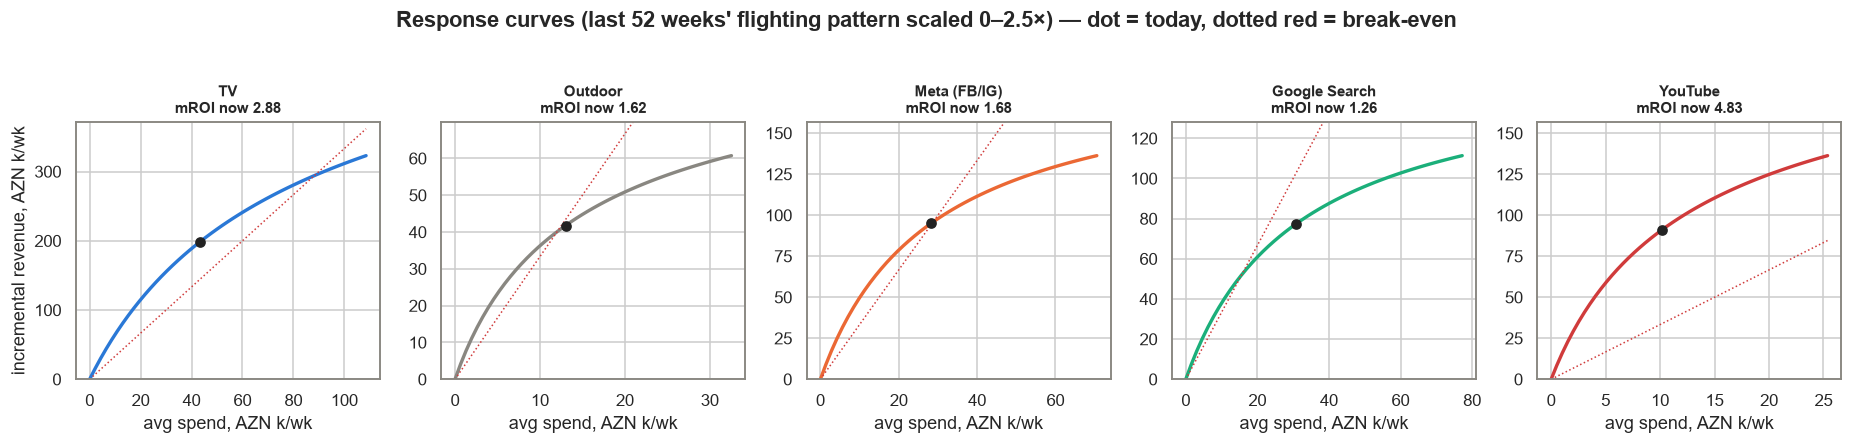

In [14]:
last = df.tail(52)
mult = np.linspace(0, 2.5, 51)
fig, axs = plt.subplots(1, 5, figsize=(17, 3.9), sharey=False)
curves = {}
for ax, c in zip(axs, CH):
    sp = model._spend(last)[c].to_numpy()
    rev = np.array([model.channel_revenue(c, sp * k).sum() for k in mult]) / 52
    curves[c] = rev
    ax.plot(sp.mean() * mult, rev, color=COL[c], lw=2.2)
    ax.scatter([sp.mean()], [model.channel_revenue(c, sp).sum() / 52], color="#222", zorder=3)
    xs = np.array([0, sp.mean() * 2.5]); ax.plot(xs, xs * BREAK_EVEN, color="#d03b3b", ls=":", lw=1)
    ax.set_title(f"{L[c]}\nmROI now {model.marginal_roi(last, c):.2f}", fontsize=10)
    ax.set_xlabel("avg spend, AZN k/wk"); ax.set_ylim(0, rev.max() * 1.15)
axs[0].set_ylabel("incremental revenue, AZN k/wk")
fig.suptitle("Response curves (last 52 weeks' flighting pattern scaled 0–2.5×) — dot = today, dotted red = break-even", fontweight="bold", y=1.03)
plt.tight_layout(); plt.savefig("images/response_curves.png", bbox_inches="tight"); plt.show()

Google Search sits on the flat part of its curve: the brand-keyword auction is already won and extra spend buys clicks that would have come anyway. YouTube and TV still have room to grow. At the margin, **only YouTube** is still above the AZN 3.33 break-even; TV is close, and Meta, outdoor and Search are well below it.

## 8. Budget optimisation

Two scenarios over the last 52 weeks' flighting pattern (each channel's weekly pattern is scaled, so timing stays realistic):
* **A — same budget, re-allocated:** each channel may move between 50% and 150% of today (larger swings are outside the data the model has seen).
* **B — profit-maximising budget:** total is free, each channel again 50–150% of today, objective = 30% × incremental revenue − spend.

In [15]:
cur_sp = model._spend(last).sum()
cur_rev = model.period_response(last, np.ones(5))
mA, revA = model.optimise(last, lo=.5, hi=1.5)
obj = lambda m: -(MARGIN * model.period_response(last, m) - (m * cur_sp.to_numpy()).sum())
resB = minimize(obj, np.ones(5), bounds=[(.5, 1.5)] * 5, method="L-BFGS-B")
mB = pd.Series(resB.x, index=CH); revB = model.period_response(last, mB.to_numpy())
S = pd.DataFrame({"today": cur_sp, "A: same budget": cur_sp * mA, "B: profit-optimal": cur_sp * mB}).rename(index=L)
S.loc["Total spend"] = S.sum()
for name, r, m in [("today", cur_rev, np.ones(5)), ("A: same budget", revA, mA), ("B: profit-optimal", revB, mB)]:
    S.loc["Media-driven revenue", name] = r
    S.loc["Media profit (30% × revenue − spend)", name] = MARGIN * r - (cur_sp * m).sum()
(S / 1000).style.format("AZN {:,.2f} M")

,today,A: same budget,B: profit-optimal
TV,AZN 2.26 M,AZN 3.28 M,AZN 1.82 M
Outdoor,AZN 0.68 M,AZN 0.49 M,AZN 0.34 M
Meta (FB/IG),AZN 1.47 M,AZN 1.13 M,AZN 0.73 M
Google Search,AZN 1.61 M,AZN 0.84 M,AZN 0.80 M
YouTube,AZN 0.53 M,AZN 0.79 M,AZN 0.78 M
Total spend,AZN 6.54 M,AZN 6.54 M,AZN 4.48 M
Media-driven revenue,AZN 26.21 M,AZN 27.56 M,AZN 22.16 M
Media profit (30% × revenue − spend),AZN 1.33 M,AZN 1.73 M,AZN 2.17 M


A: revenue +AZN 1.36 M (+1.6% of total revenue), media profit +AZN 0.41 M
B: spend -31.5%, revenue -4.05 M (-4.8% of total), media profit +AZN 0.84 M


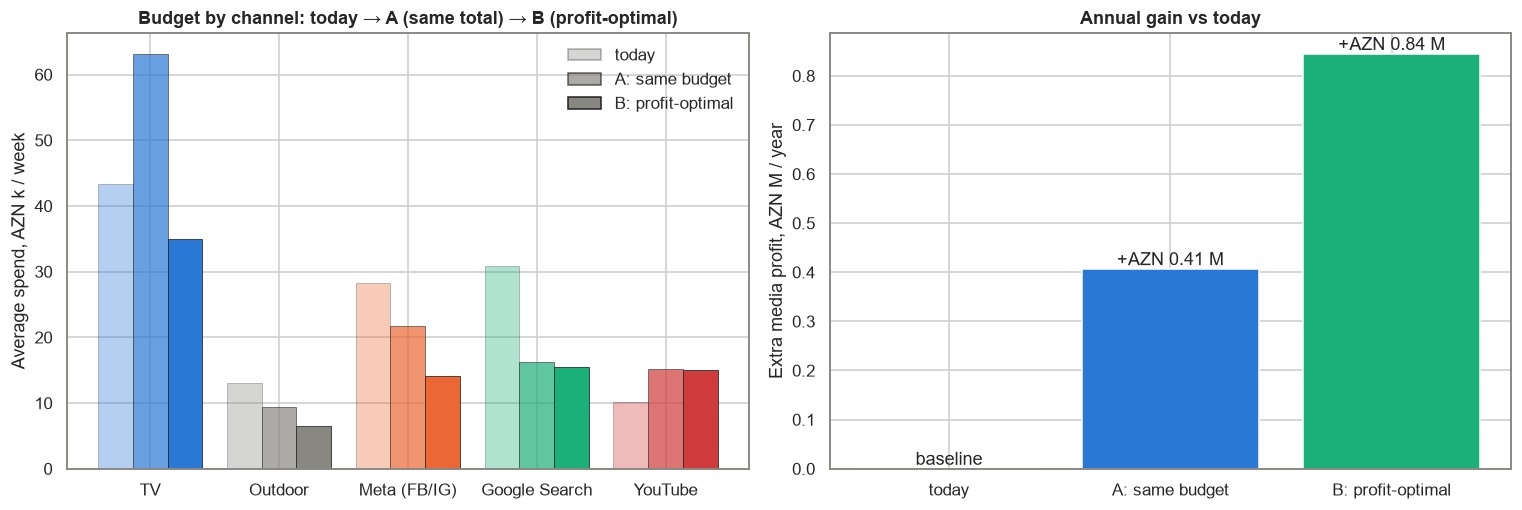

In [16]:
upA = revA - cur_rev; upB = revB - cur_rev
gpA = S.loc["Media profit (30% × revenue − spend)", "A: same budget"] - S.loc["Media profit (30% × revenue − spend)", "today"]
gpB = S.loc["Media profit (30% × revenue − spend)", "B: profit-optimal"] - S.loc["Media profit (30% × revenue − spend)", "today"]
print(f"A: revenue +AZN {upA / 1000:,.2f} M ({upA / last.revenue_azn_k.sum():+.1%} of total revenue), media profit +AZN {gpA / 1000:,.2f} M")
print(f"B: spend {S.loc['Total spend', 'B: profit-optimal'] / S.loc['Total spend', 'today'] - 1:+.1%}, revenue {upB / 1000:+,.2f} M ({upB / last.revenue_azn_k.sum():+.1%} of total), media profit +AZN {gpB / 1000:,.2f} M")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
x = np.arange(5); w = .27
for i, (col, a) in enumerate([("today", .35), ("A: same budget", .7), ("B: profit-optimal", 1)]):
    ax[0].bar(x + (i - 1) * w, S.loc[[L[c] for c in CH], col] / 52, w, color=[COL[c] for c in CH], alpha=a,
              edgecolor="#222", lw=.5, label=col)
ax[0].set_xticks(x, [L[c] for c in CH]); ax[0].set_ylabel("Average spend, AZN k / week")
from matplotlib.patches import Patch
ax[0].legend([Patch(facecolor="#898781", alpha=a, edgecolor="#222") for a in (.35, .7, 1)], ["today", "A: same budget", "B: profit-optimal"], frameon=False); ax[0].set_title("Budget by channel: today → A (same total) → B (profit-optimal)")
vals = [0, gpA / 1000, gpB / 1000]
bars = ax[1].bar(["today", "A: same budget", "B: profit-optimal"], vals, color=["#d9d6cf", "#2a78d6", "#1baf7a"])
for b, v in zip(bars, vals): ax[1].text(b.get_x() + b.get_width() / 2, v, f"+AZN {v:,.2f} M" if v else "baseline", ha="center", va="bottom")
ax[1].set_ylabel("Extra media profit, AZN M / year"); ax[1].set_title("Annual gain vs today")
plt.tight_layout(); plt.savefig("images/budget_reallocation.png", bbox_inches="tight"); plt.show()

## 9. Findings & recommendations

In [17]:
f = lambda c: f"ROI {roi[c]:.2f} (90% CI {boot.quantile(.05)[c]:.1f}–{boot.quantile(.95)[c]:.1f}), mROI {mroi[c]:.2f}"
rec = pd.DataFrame([
 ("Measurement", f"Platforms credit {K['Sum of platform-attributed revenue (3 digital channels)']} to 3 channels; Search ROAS {platform['google_search']:.1f} vs MMM {roi['google_search']:.1f}",
  "Stop using platform ROAS for budget allocation; report MMM ROI and mROI quarterly"),
 ("YouTube", f(c="youtube") + "; least saturated", "The only channel with mROI above break-even: raise to the 150% cap in both scenarios, then test beyond it with a geo experiment"),
 ("TV", f(c="tv") + f"; half-life {params.loc['TV', 'half-life (weeks)']:.1f} weeks", "Biggest driver and profitable on average; mROI is just below 3.33, so extra TV buys revenue but not profit: add only under a growth goal (A), otherwise trim slightly (B)"),
 ("Google Search", f(c="google_search") + "; on the flat part of the curve", "Cut by about half (both scenarios move it to ~50%): trim brand-keyword and generic bids that harvest demand created elsewhere"),
 ("Meta", f(c="meta"), "Average ROI is at break-even, the margin is not: trim towards 50-75% and run a proper geo-holdout (the Dec go-dark test was confounded by seasonality)"),
 ("Outdoor", f(c="outdoor") + "; the ground-truth check shows the MMM overstates it", "Cut to the minimum contract and run a city-split test before renewing"),
 ("Budget", f"Same budget re-allocated: +AZN {gpA / 1000:,.2f} M media profit/year; profit-optimal (spend {S.loc['Total spend', 'B: profit-optimal'] / S.loc['Total spend', 'today'] - 1:+.0%}): +AZN {gpB / 1000:,.2f} M", "Growth goal → A (same total, more revenue and profit); profit goal → B. Either way move ±25% per quarter and re-fit the model after each step"),
], columns=["Area", "Evidence", "Recommendation"])
pd.set_option("display.max_colwidth", 200); rec

,Area,Evidence,Recommendation
0,Measurement,Platforms credit 31.5% of all revenue to 3 channels; Search ROAS 8.3 vs MMM 2.5,Stop using platform ROAS for budget allocation; report MMM ROI and mROI quarterly
1,YouTube,"ROI 8.98 (90% CI 7.7–10.2), mROI 4.76; least saturated","The only channel with mROI above break-even: raise to the 150% cap in both scenarios, then test beyond it with a geo experiment"
2,TV,"ROI 4.61 (90% CI 4.3–4.9), mROI 2.90; half-life 1.1 weeks","Biggest driver and profitable on average; mROI is just below 3.33, so extra TV buys revenue but not profit: add only under a growth goal (A), otherwise trim slightly (B)"
3,Google Search,"ROI 2.49 (90% CI 1.2–3.9), mROI 1.23; on the flat part of the curve",Cut by about half (both scenarios move it to ~50%): trim brand-keyword and generic bids that harvest demand created elsewhere
4,Meta,"ROI 3.36 (90% CI 2.6–4.3), mROI 1.69","Average ROI is at break-even, the margin is not: trim towards 50-75% and run a proper geo-holdout (the Dec go-dark test was confounded by seasonality)"
5,Outdoor,"ROI 3.08 (90% CI 2.2–4.0), mROI 1.48; the ground-truth check shows the MMM overstates it",Cut to the minimum contract and run a city-split test before renewing
6,Budget,Same budget re-allocated: +AZN 0.41 M media profit/year; profit-optimal (spend -31%): +AZN 0.84 M,"Growth goal → A (same total, more revenue and profit); profit goal → B. Either way move ±25% per quarter and re-fit the model after each step"


**Bottom line:** the platform dashboards point the budget in the wrong direction — towards Google Search, which mostly captures demand created by TV and YouTube. The MMM says upper-funnel video (YouTube, TV) earns the most per extra manat, Search and outdoor are saturated or below break-even, and simply re-allocating the same budget raises media profit without spending more. Cutting the saturated channels raises profit further but costs revenue, so it is a growth-vs-profit decision for management.

*Caveats: 156 weekly points can identify only a handful of parameters, so priors matter and the widest intervals (outdoor, Meta) should be calibrated with experiments; Hill shape is fixed at 1 while the true TV curve is S-shaped; the optimiser extrapolates only within 50–150% of observed spend; 30% gross margin is an assumption; competitor spend is only a promo flag.*